In [1]:
import pandas as pd

df=pd.read_csv("train.csv")

In [2]:
print(df)

      Customer ID               Name Gender  Age  Income (USD)  \
0         C-36995   Frederica Shealy      F   56       1933.05   
1         C-33999  America Calderone      M   32       4952.91   
2          C-3770      Rosetta Verne      F   65        988.19   
3         C-26480         Zoe Chitty      F   65           NaN   
4         C-23459       Afton Venema      F   31       2614.77   
...           ...                ...    ...  ...           ...   
29995     C-43723  Angelyn Clevenger      M   38       4969.41   
29996     C-32511       Silas Slaugh      M   20       1606.88   
29997      C-5192       Carmelo Lone      F   49           NaN   
29998     C-12172      Carolann Osby      M   38       2417.71   
29999     C-33003  Bridget Garibaldi      F   63       3068.24   

      Income Stability            Profession     Type of Employment  \
0                  Low               Working            Sales staff   
1                  Low               Working                    N

In [3]:
df.columns

Index(['Customer ID', 'Name', 'Gender', 'Age', 'Income (USD)',
       'Income Stability', 'Profession', 'Type of Employment', 'Location',
       'Loan Amount Request (USD)', 'Current Loan Expenses (USD)',
       'Expense Type 1', 'Expense Type 2', 'Dependents', 'Credit Score',
       'No. of Defaults', 'Has Active Credit Card', 'Property ID',
       'Property Age', 'Property Type', 'Property Location', 'Co-Applicant',
       'Property Price', 'Loan Sanction Amount (USD)'],
      dtype='str')

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 24 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   Customer ID                  30000 non-null  str    
 1   Name                         30000 non-null  str    
 2   Gender                       29947 non-null  str    
 3   Age                          30000 non-null  int64  
 4   Income (USD)                 25424 non-null  float64
 5   Income Stability             28317 non-null  str    
 6   Profession                   30000 non-null  str    
 7   Type of Employment           22730 non-null  str    
 8   Location                     30000 non-null  str    
 9   Loan Amount Request (USD)    30000 non-null  float64
 10  Current Loan Expenses (USD)  29828 non-null  float64
 11  Expense Type 1               30000 non-null  str    
 12  Expense Type 2               30000 non-null  str    
 13  Dependents                 

In [5]:
df.isnull().sum()

Customer ID                       0
Name                              0
Gender                           53
Age                               0
Income (USD)                   4576
Income Stability               1683
Profession                        0
Type of Employment             7270
Location                          0
Loan Amount Request (USD)         0
Current Loan Expenses (USD)     172
Expense Type 1                    0
Expense Type 2                    0
Dependents                     2493
Credit Score                   1703
No. of Defaults                   0
Has Active Credit Card         1566
Property ID                       0
Property Age                   4850
Property Type                     0
Property Location               356
Co-Applicant                      0
Property Price                    0
Loan Sanction Amount (USD)      340
dtype: int64

In [6]:
df.duplicated().sum()

np.int64(0)

In [7]:
num_colmn=df.select_dtypes( include=['int64','float64'] ).columns #binaryco

In [8]:
print(num_colmn)

Index(['Age', 'Income (USD)', 'Loan Amount Request (USD)',
       'Current Loan Expenses (USD)', 'Dependents', 'Credit Score',
       'No. of Defaults', 'Property ID', 'Property Age', 'Property Type',
       'Co-Applicant', 'Property Price', 'Loan Sanction Amount (USD)'],
      dtype='str')


In [11]:
cat_colmn=df.select_dtypes( include=['object','str'] ).columns
print(cat_colmn)#binaryco

Index(['Customer ID', 'Name', 'Gender', 'Income Stability', 'Profession',
       'Type of Employment', 'Location', 'Expense Type 1', 'Expense Type 2',
       'Has Active Credit Card', 'Property Location'],
      dtype='str')


In [20]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
import numpy as np

from sklearn.model_selection import train_test_split



X=df.drop(columns=['Loan Sanction Amount (USD)'])
y=df['Loan Sanction Amount (USD)']


num_cols=X.select_dtypes(include=np.number).columns.tolist()
cat_cols=X.select_dtypes(exclude=np.number).columns.tolist()


X_train,X_test,y_train,y_test=train_test_split( X,y,test_size=0.2, random_state=42 )





num_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

cat_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

preprocessor = ColumnTransformer([
    ("num", num_pipe, num_cols),
    ("cat", cat_pipe, cat_cols)
])

In [21]:
X_train_encoded=preprocessor.fit_transform(X_train)
X_test_encoded = preprocessor.transform(X_test)

In [22]:
print("X_train_encoded shape:", X_train_encoded.shape)
print("X_test_encoded shape :", X_test_encoded.shape)

X_train_encoded shape: (24000, 48054)
X_test_encoded shape : (6000, 48054)


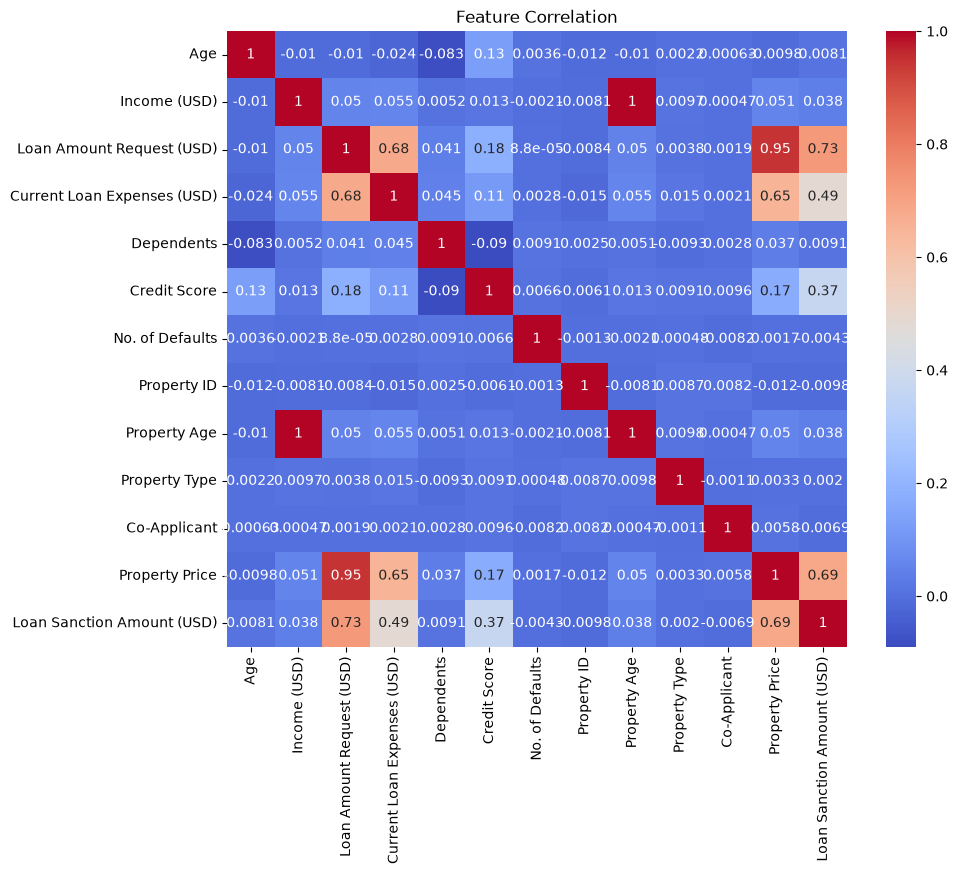

In [29]:
import matplotlib.pyplot as plt
import seaborn as sns
plt.figure(figsize=(10, 8))
sns.heatmap(df.select_dtypes(include="number").corr(),annot=True,cmap="coolwarm")
plt.title("Feature Correlation")
plt.show()

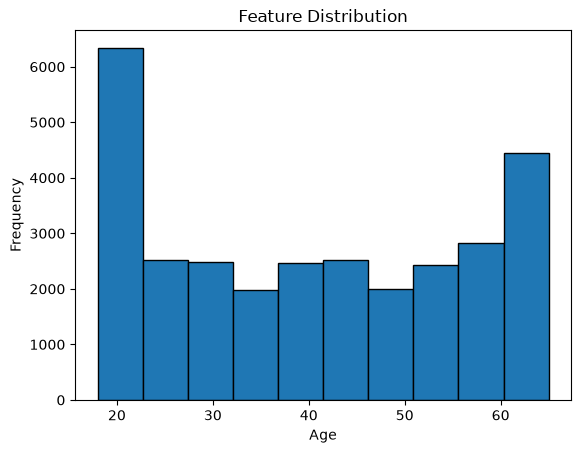

In [30]:
import matplotlib.pyplot as plt

# Pick a key numeric column (e.g., first numeric column or 'Income (USD)')
feature = num_cols[0]

plt.hist(X[feature].dropna(), bins=10, edgecolor="black")
plt.title("Feature Distribution")
plt.xlabel(feature)
plt.ylabel("Frequency")
plt.show()

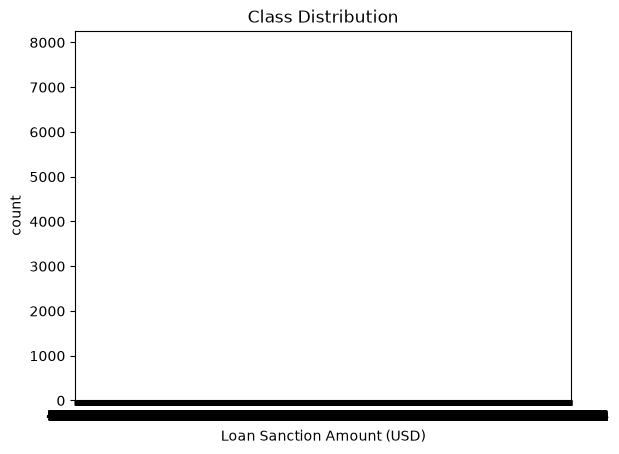

In [32]:
import matplotlib.pyplot as plt
import seaborn as sns

y=df['Loan Sanction Amount (USD)']
sns.countplot(x=y)
plt.title("Class Distribution")
plt.show()